# 02. Program-defined temporal phenotypes and archetypes

This notebook adds analyses inspired by asynchronous-development studies, but implemented using curated cNMF programs. It requires the output matrices from Notebook 01 or will load the cNMF spreadsheet again if needed.

In [1]:

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from scipy.cluster.hierarchy import linkage, leaves_list, dendrogram
from scipy.spatial.distance import pdist
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap

try:
    from adjustText import adjust_text
    HAS_ADJUST_TEXT = True
except Exception:
    HAS_ADJUST_TEXT = False

pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 80)
plt.rcParams['svg.fonttype'] = 'none'   # keep text editable in Illustrator
plt.rcParams['pdf.fonttype'] = 42       # keep text editable in Illustrator
plt.rcParams['font.family'] = 'DejaVu Sans'


In [2]:

# ==============================
# User settings
# ==============================
CNMF_XLSX = "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/per_day_umaps/data/cNMF_50_0_2_032526_6co.xlsx"
ASSOC_SHEET = "Perturbation Association 1"
PROGRAM_ANNOTATION_CSV = "curated_program_annotations_from_uploaded_sheet.csv"

OUTDIR = "outputs_program_level_temporal_phenotypes_v4"
os.makedirs(OUTDIR, exist_ok=True)

# Statistical thresholds for program effect significance.
FDR_CUTOFF = 0.05
EFFECT_CUTOFF = 0.0  # set to e.g. 0.15 or 0.25 if you want stricter tags

# Target groups for focused figures.
HIPPO_TARGETS = ["NF2", "LATS2", "SAV1", "TAOK1", "AMOTL2"]
BMP_TGF_TARGETS = ["SMAD1", "SMAD4", "SMAD5", "LEMD3", "BMPR1A", "ACVR2A", "ACVR1B", "ACVR2B"]
EC_TARGETS = ["KDR", "ETV2", "ERG", "FLI1", "TAL1", "CDH5", "SOX17"]

# Program axes requested by Jesse/Kyle discussions.
PROGRAM_ID = {
    "P7": 7, "P22": 22, "P29": 29,
    "P28": 28, "P13": 13, "P30": 30, "P48": 48, "P33": 33,
    "P15": 15, "P14": 14, "P17": 17,
    "P34": 34, "P27": 27,
    "P2": 2, "P3": 3, "P8": 8, "P11": 11,
}
EC_PROGRAMS = [2, 3, 8, 11]


In [3]:

def clean_day(x):
    s = str(x).strip().lower().replace("day", "d").replace(" ", "")
    if s in ["0", "0.0", "d0"]: return "D0"
    if s in ["1", "1.0", "d1"]: return "D1"
    if s in ["2", "2.0", "d2"]: return "D2"
    if s in ["3", "3.0", "d3"]: return "D3"
    return str(x).strip().upper()


def infer_col(df, candidates, required=True):
    lookup = {str(c).lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lookup:
            return lookup[cand.lower()]
    for col in df.columns:
        cl = str(col).lower()
        for cand in candidates:
            if cand.lower() in cl:
                return col
    if required:
        raise ValueError(f"Could not infer column. Tried {candidates}. Available: {df.columns.tolist()}")
    return None


def standardize_assoc_table(raw):
    df = raw.copy().dropna(axis=0, how='all').dropna(axis=1, how='all')
    target_col = infer_col(df, ["target_name", "target", "grna_target", "gene", "gene_symbol", "perturbation"])
    program_col = infer_col(df, ["program_name", "program", "program_id", "cnmf_program", "response", "component"])
    effect_col = infer_col(df, ["approx_log2FC", "approx_log2fc", "effect", "effect_size", "log2fc", "log_2_fold_change", "coef", "beta", "estimate"])
    fdr_col = infer_col(df, ["adj_pval", "fdr", "q_value", "qval", "padj", "adjusted_p_value"], required=False)
    p_col = infer_col(df, ["p_value", "pval", "p.value", "p"], required=False)
    day_col = infer_col(df, ["Sample", "sample", "day", "diff_day", "timepoint"], required=False)

    out = pd.DataFrame({
        "target": df[target_col].astype(str).str.strip(),
        "program_id": pd.to_numeric(df[program_col], errors="coerce"),
        "effect": pd.to_numeric(df[effect_col], errors="coerce"),
    })
    out["fdr"] = pd.to_numeric(df[fdr_col], errors="coerce") if fdr_col else np.nan
    out["p_value"] = pd.to_numeric(df[p_col], errors="coerce") if p_col else np.nan
    out["day"] = df[day_col].map(clean_day) if day_col else np.nan
    out = out.dropna(subset=["target", "program_id", "effect"]).copy()
    out["program_id"] = out["program_id"].astype(int)
    return out


def load_curated_data(cnmf_xlsx=CNMF_XLSX, assoc_sheet=ASSOC_SHEET, annotation_csv=PROGRAM_ANNOTATION_CSV):
    ann = pd.read_csv(annotation_csv)
    ann["program_id"] = ann["program_id"].astype(int)
    ann["program_label"] = ann["program_label"].astype(str)
    ann["program_stage"] = ann["program_stage"].astype(str)
    # day for filtering; assumed first token of program_stage like D2/LM_vascular
    ann["curated_day"] = ann["program_stage"].str.extract(r"(D[0-3])", expand=False)
    ann["program_display"] = ann["program_label"] + "\n" + ann["Name"].astype(str)

    raw = pd.read_excel(cnmf_xlsx, sheet_name=assoc_sheet)
    assoc = standardize_assoc_table(raw)
    merged = assoc.merge(ann, on="program_id", how="inner")
    # match effect day to curated day when day is available
    if merged["day"].notna().any():
        merged = merged[(merged["day"] == merged["curated_day"]) | merged["curated_day"].isna()].copy()
    merged["significant"] = merged["fdr"] < FDR_CUTOFF
    return ann, assoc, merged


def make_effect_and_fdr_matrices(curated):
    effect = curated.pivot_table(index="target", columns="program_id", values="effect", aggfunc="mean")
    fdr = curated.pivot_table(index="target", columns="program_id", values="fdr", aggfunc="min")
    return effect, fdr


def program_order_from_annotation(ann):
    stage_order = {"D0/pluripotency":0, "D1/primitive_streak":1, "D2/LM_vascular":2, "D3/alternative":3, "D3/endothelial":4}
    tmp = ann.copy()
    tmp["stage_order"] = tmp["program_stage"].map(stage_order).fillna(99)
    tmp = tmp.sort_values(["stage_order", "program_id"])
    return tmp["program_id"].tolist()


def get_present_cols(mat, cols):
    return [c for c in cols if c in mat.columns]


def mean_cols(mat, cols):
    cols = get_present_cols(mat, cols)
    if len(cols) == 0:
        return pd.Series(np.nan, index=mat.index)
    return mat[cols].mean(axis=1)


def effect_col(mat, program_id):
    if program_id in mat.columns:
        return mat[program_id]
    return pd.Series(np.nan, index=mat.index)


def sig_col(fdr, program_id):
    if program_id in fdr.columns:
        return fdr[program_id] < FDR_CUTOFF
    return pd.Series(False, index=fdr.index)


def plot_heatmap(matrix, row_order=None, col_order=None, title="", figsize=(9, 8), center=0, cmap="RdBu_r", out=None, vlim=None):
    mat = matrix.copy()
    if row_order is not None:
        mat = mat.loc[[r for r in row_order if r in mat.index]]
    if col_order is not None:
        mat = mat[[c for c in col_order if c in mat.columns]]
    vals = mat.values.astype(float)
    if vlim is None:
        vmax = np.nanpercentile(np.abs(vals), 98)
        vmax = max(vmax, 0.5)
    else:
        vmax = vlim
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(vals, aspect="auto", cmap=cmap, norm=TwoSlopeNorm(vmin=-vmax, vcenter=center, vmax=vmax))
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_xticks(np.arange(mat.shape[1]))
    ax.set_xticklabels(mat.columns, rotation=90, fontsize=8)
    ax.set_yticks(np.arange(mat.shape[0]))
    ax.set_yticklabels(mat.index, fontsize=6)
    cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    cbar.set_label("effect size", fontsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.tight_layout()
    if out:
        fig.savefig(out + ".png", dpi=300, bbox_inches="tight")
        fig.savefig(out + ".pdf", bbox_inches="tight")
        fig.savefig(out + ".svg", bbox_inches="tight")
    plt.show()
    return fig, ax


def cluster_rows(mat, metric="euclidean", method="average"):
    vals = mat.fillna(0).values
    if vals.shape[0] < 3:
        return mat.index.tolist()
    Z = linkage(pdist(vals, metric=metric), method=method)
    return mat.index[leaves_list(Z)].tolist()


## Load curated effects

In [4]:

ann, assoc_all, curated = load_curated_data()
effect_mat, fdr_mat = make_effect_and_fdr_matrices(curated)
program_order = program_order_from_annotation(ann)
effect_mat = effect_mat[[c for c in program_order if c in effect_mat.columns]]
fdr_mat = fdr_mat[[c for c in program_order if c in fdr_mat.columns]]
program_label_map = ann.set_index("program_id")["program_label"].to_dict()
program_stage_map = ann.set_index("program_id")["curated_day"].to_dict()
os.makedirs(OUTDIR, exist_ok=True)
print(effect_mat.shape)


(299, 17)


## Program group summaries

Collapse curated programs into expert-defined biological groups for easier interpretation.

In [5]:

program_groups = {
    "D0_pluripotency": [7, 22, 29],
    "D1_primitive_streak": [28, 13, 30, 48, 33],
    "D2_vascular_progenitor_P15": [15],
    "D2_standard_lateral_mesoderm_P14": [14],
    "D2_YAP_TAZ_lateral_mesoderm_P17": [17],
    "D3_YAP_TAZ_mesenchyme_P34": [34],
    "D3_ECM_mesenchyme_P27": [27],
    "D3_EC_endpoint": [2, 3, 8, 11],
}

group_effect = pd.DataFrame({g: mean_cols(effect_mat, pids) for g, pids in program_groups.items()})
# group fdr = min FDR among programs in the group
group_fdr = pd.DataFrame({g: fdr_mat[get_present_cols(fdr_mat, pids)].min(axis=1) if len(get_present_cols(fdr_mat, pids)) else np.nan for g, pids in program_groups.items()})
group_effect.to_csv(os.path.join(OUTDIR, "target_by_program_group_effect.csv"))
group_fdr.to_csv(os.path.join(OUTDIR, "target_by_program_group_min_fdr.csv"))
display(group_effect.head())


,D0_pluripotency,D1_primitive_streak,D2_vascular_progenitor_P15,D2_standard_lateral_mesoderm_P14,D2_YAP_TAZ_lateral_mesoderm_P17,D3_YAP_TAZ_mesenchyme_P34,D3_ECM_mesenchyme_P27,D3_EC_endpoint
target,,,,,,,,
ACAA1,-0.008648,-0.322046,1.273920,0.988805,-0.659772,-0.539104,-0.590488,0.914975
ACTL7B,-0.218645,0.283340,0.216181,0.488880,-0.767090,-1.098780,-0.416886,0.613967
ACVR1B,-0.007445,-1.040668,-0.876915,0.413744,1.175025,1.573374,-0.265476,-1.423613
ACVR2A,-0.023278,0.334574,-1.321533,-4.429201,-0.764416,1.298657,-0.850912,-3.357090
ACVR2B,-0.058104,-0.064147,-1.703856,-2.706774,1.133876,1.412255,-1.401973,-1.158800


## Directional program axes

These are program-defined analogues of delayed/split/diverted development. They avoid global pseudotime.

In [6]:

axes_df = pd.DataFrame(index=effect_mat.index)
axes_df["D2_P17_minus_P15"] = effect_col(effect_mat, 17) - effect_col(effect_mat, 15)
axes_df["D2_P17_minus_P14"] = effect_col(effect_mat, 17) - effect_col(effect_mat, 14)
axes_df["D2_P14_minus_P15"] = effect_col(effect_mat, 14) - effect_col(effect_mat, 15)
axes_df["D3_P34_minus_EC"] = effect_col(effect_mat, 34) - mean_cols(effect_mat, EC_PROGRAMS)
axes_df["D3_P27_minus_EC"] = effect_col(effect_mat, 27) - mean_cols(effect_mat, EC_PROGRAMS)
axes_df["YAP_diversion_axis"] = mean_cols(effect_mat, [17, 34]) - mean_cols(effect_mat, [15, 2, 3, 8, 11])
axes_df.to_csv(os.path.join(OUTDIR, "target_directional_program_axes.csv"))
display(axes_df.head())


,D2_P17_minus_P15,D2_P17_minus_P14,D2_P14_minus_P15,D3_P34_minus_EC,D3_P27_minus_EC,YAP_diversion_axis
target,,,,,,
ACAA1,-1.933692,-1.648577,-0.285115,-1.454079,-1.505463,-1.586202
ACTL7B,-0.983271,-1.255970,0.272699,-1.712748,-1.030853,-1.467345
ACVR1B,2.051940,0.761280,1.290659,2.996987,1.158137,2.688473
ACVR2A,0.557117,3.664785,-3.107669,4.655747,2.506179,3.217099
ACVR2B,2.837732,3.840650,-1.002918,2.571055,-0.243173,2.540877


## Developmental age and asynchrony scores

Inspired by asynchronous-development analyses: quantify whether positive and negative effects are concentrated in earlier or later curated programs.

In [7]:

# map programs to day indices
program_day_index = {pid: {"D0":0, "D1":1, "D2":2, "D3":3}.get(program_stage_map.get(pid), np.nan) for pid in effect_mat.columns}
day_index = pd.Series(program_day_index)

scores = pd.DataFrame(index=effect_mat.index)
E = effect_mat.copy()
pos = E.clip(lower=0)
neg = (-E).clip(lower=0)

# Weighted average developmental day for positive and negative program effects.
pos_weight = pos.sum(axis=1).replace(0, np.nan)
neg_weight = neg.sum(axis=1).replace(0, np.nan)
scores["positive_effect_developmental_age"] = pos.mul(day_index, axis=1).sum(axis=1) / pos_weight
scores["negative_effect_developmental_age"] = neg.mul(day_index, axis=1).sum(axis=1) / neg_weight
scores["heterochrony_score_pos_late_neg_early"] = scores["positive_effect_developmental_age"] - scores["negative_effect_developmental_age"]

# Asynchrony/spread scores.
stage_mean = pd.DataFrame(index=E.index)
for day, pids in ann.groupby("curated_day")["program_id"]:
    stage_mean[day] = mean_cols(E, list(pids))
scores["stage_mean_effect_sd"] = stage_mean.std(axis=1)
scores["program_effect_sd"] = E.std(axis=1)
scores["effect_range"] = E.max(axis=1) - E.min(axis=1)

scores = pd.concat([scores, axes_df], axis=1)
scores.to_csv(os.path.join(OUTDIR, "target_temporal_phenotype_scores.csv"))
display(scores.head())


,positive_effect_developmental_age,negative_effect_developmental_age,heterochrony_score_pos_late_neg_early,stage_mean_effect_sd,program_effect_sd,effect_range,D2_P17_minus_P15,D2_P17_minus_P14,D2_P14_minus_P15,D3_P34_minus_EC,D3_P27_minus_EC,YAP_diversion_axis
target,,,,,,,,,,,,
ACAA1,2.420505,1.659511,0.760994,0.395545,0.738295,2.147003,-1.933692,-1.648577,-0.285115,-1.454079,-1.505463,-1.586202
ACTL7B,2.109401,1.917790,0.191611,0.218325,0.578750,2.097419,-0.983271,-1.255970,0.272699,-1.712748,-1.030853,-1.467345
ACVR1B,2.018874,1.942048,0.076826,0.599852,1.211056,4.587819,2.051940,0.761280,1.290659,2.996987,1.158137,2.688473
ACVR2A,1.651555,2.619720,-0.968165,1.349251,1.875679,5.780729,0.557117,3.664785,-3.107669,4.655747,2.506179,3.217099
ACVR2B,1.816945,2.242738,-0.425793,0.519388,1.131954,4.119029,2.837732,3.840650,-1.002918,2.571055,-0.243173,2.540877


## First affected day and strongest affected programs

In [8]:

sig = fdr_mat < FDR_CUTOFF
first_day_records = []
for target in effect_mat.index:
    sig_pids = [pid for pid in effect_mat.columns if sig.loc[target, pid]]
    days = [program_stage_map.get(pid) for pid in sig_pids]
    day_order = {"D0":0, "D1":1, "D2":2, "D3":3}
    valid_days = [d for d in days if d in day_order]
    first_day = min(valid_days, key=lambda d: day_order[d]) if valid_days else "none"
    strongest_pos_pid = effect_mat.loc[target].idxmax()
    strongest_neg_pid = effect_mat.loc[target].idxmin()
    first_day_records.append({
        "target": target,
        "first_affected_day": first_day,
        "n_significant_curated_programs": len(sig_pids),
        "strongest_positive_program_id": strongest_pos_pid,
        "strongest_positive_program": program_label_map.get(strongest_pos_pid, f"P{strongest_pos_pid}"),
        "strongest_positive_effect": effect_mat.loc[target, strongest_pos_pid],
        "strongest_negative_program_id": strongest_neg_pid,
        "strongest_negative_program": program_label_map.get(strongest_neg_pid, f"P{strongest_neg_pid}"),
        "strongest_negative_effect": effect_mat.loc[target, strongest_neg_pid],
    })
first_day_df = pd.DataFrame(first_day_records).set_index("target")
first_day_df.to_csv(os.path.join(OUTDIR, "target_first_affected_day_and_strongest_programs.csv"))
display(first_day_df.head())
display(first_day_df["first_affected_day"].value_counts())


,first_affected_day,n_significant_curated_programs,strongest_positive_program_id,strongest_positive_program,strongest_positive_effect,strongest_negative_program_id,strongest_negative_program,strongest_negative_effect
target,,,,,,,,
ACAA1,D3,2,15,P15,1.273920,48,P48,-0.873082
ACTL7B,D3,1,33,P33,0.998639,34,P34,-1.098780
ACVR1B,D1,6,34,P34,1.573374,30,P30,-3.014445
ACVR2A,D2,5,48,P48,1.351528,14,P14,-4.429201
ACVR2B,D2,3,34,P34,1.412255,14,P14,-2.706774


first_affected_day
none    115
D3       83
D0       62
D2       23
D1       16
Name: count, dtype: int64

## Rule-based phenotype tags

These are deliberately program-defined. Adjust thresholds if desired.

In [9]:

def eff(target, pid):
    return effect_mat.loc[target, pid] if pid in effect_mat.columns else np.nan

def is_sig(target, pid):
    return bool(fdr_mat.loc[target, pid] < FDR_CUTOFF) if pid in fdr_mat.columns else False

def tag_target(target):
    tags = []
    # D0/D1
    if any(is_sig(target, pid) and eff(target, pid) > EFFECT_CUTOFF for pid in [7,22,29]):
        tags.append("pluripotency retention / delayed exit")
    if any(is_sig(target, pid) for pid in [28,13,30,48,33]):
        tags.append("D1 primitive-streak / early mesoderm patterning")
    # D2
    if is_sig(target, 15) and eff(target, 15) < -EFFECT_CUTOFF:
        tags.append("loss of P15 vascular progenitor program")
    if is_sig(target, 14) and eff(target, 14) > EFFECT_CUTOFF:
        tags.append("increased standard lateral mesoderm P14")
    if is_sig(target, 17) and eff(target, 17) > EFFECT_CUTOFF:
        tags.append("increased YAP/TAZ-induced lateral mesoderm P17")
    if is_sig(target, 17) and eff(target, 17) > EFFECT_CUTOFF and is_sig(target, 15) and eff(target, 15) < -EFFECT_CUTOFF:
        tags.append("D2 split/diversion: P17 up, P15 down")
    # D3
    if is_sig(target, 34) and eff(target, 34) > EFFECT_CUTOFF:
        tags.append("increased P34 YAP/TAZ mesenchyme")
    if is_sig(target, 27) and eff(target, 27) > EFFECT_CUTOFF:
        tags.append("increased P27 ECM mesenchyme")
    ec_down = any(is_sig(target, pid) and eff(target, pid) < -EFFECT_CUTOFF for pid in EC_PROGRAMS if pid in effect_mat.columns)
    if ec_down:
        tags.append("loss of D3 endothelial endpoint programs")
    if is_sig(target, 34) and eff(target, 34) > EFFECT_CUTOFF and ec_down:
        tags.append("D3 diversion: P34 up, EC down")
    if len(tags) == 0:
        tags.append("no strong curated phenotype tag")
    return "; ".join(tags)

phenotypes = pd.concat([scores, first_day_df], axis=1)
phenotypes["phenotype_tags"] = [tag_target(t) for t in phenotypes.index]
phenotypes.to_csv(os.path.join(OUTDIR, "target_program_defined_phenotype_tags.csv"))
display(phenotypes.head())
display(phenotypes["phenotype_tags"].value_counts().head(20))


,positive_effect_developmental_age,negative_effect_developmental_age,heterochrony_score_pos_late_neg_early,stage_mean_effect_sd,program_effect_sd,effect_range,D2_P17_minus_P15,D2_P17_minus_P14,D2_P14_minus_P15,D3_P34_minus_EC,D3_P27_minus_EC,YAP_diversion_axis,first_affected_day,n_significant_curated_programs,strongest_positive_program_id,strongest_positive_program,strongest_positive_effect,strongest_negative_program_id,strongest_negative_program,strongest_negative_effect,phenotype_tags
target,,,,,,,,,,,,,,,,,,,,,
ACAA1,2.420505,1.659511,0.760994,0.395545,0.738295,2.147003,-1.933692,-1.648577,-0.285115,-1.454079,-1.505463,-1.586202,D3,2,15,P15,1.273920,48,P48,-0.873082,no strong curated phenotype tag
ACTL7B,2.109401,1.917790,0.191611,0.218325,0.578750,2.097419,-0.983271,-1.255970,0.272699,-1.712748,-1.030853,-1.467345,D3,1,33,P33,0.998639,34,P34,-1.098780,no strong curated phenotype tag
ACVR1B,2.018874,1.942048,0.076826,0.599852,1.211056,4.587819,2.051940,0.761280,1.290659,2.996987,1.158137,2.688473,D1,6,34,P34,1.573374,30,P30,-3.014445,D1 primitive-streak / early mesoderm patternin...
ACVR2A,1.651555,2.619720,-0.968165,1.349251,1.875679,5.780729,0.557117,3.664785,-3.107669,4.655747,2.506179,3.217099,D2,5,48,P48,1.351528,14,P14,-4.429201,loss of D3 endothelial endpoint programs
ACVR2B,1.816945,2.242738,-0.425793,0.519388,1.131954,4.119029,2.837732,3.840650,-1.002918,2.571055,-0.243173,2.540877,D2,3,34,P34,1.412255,14,P14,-2.706774,loss of P15 vascular progenitor program


phenotype_tags
no strong curated phenotype tag                                                                                                                                                     189
loss of D3 endothelial endpoint programs                                                                                                                                             18
increased P27 ECM mesenchyme; loss of D3 endothelial endpoint programs                                                                                                               10
pluripotency retention / delayed exit                                                                                                                                                 9
increased P27 ECM mesenchyme                                                                                                                                                          7
increased P34 YAP/TAZ mesenchyme; loss of D3 endothelial endpoint

## Phenotype score heatmap

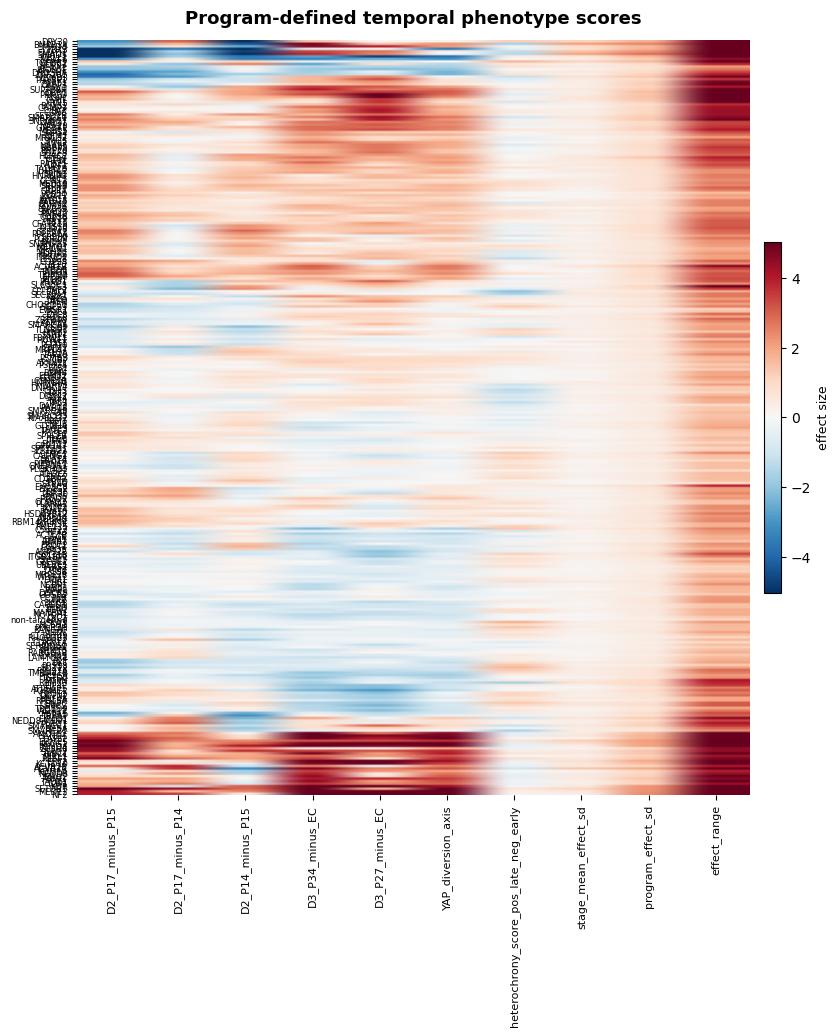

(<Figure size 850x1046.5 with 2 Axes>,
 <Axes: title={'center': 'Program-defined temporal phenotype scores'}>)

In [10]:

score_cols = [
    "D2_P17_minus_P15", "D2_P17_minus_P14", "D2_P14_minus_P15",
    "D3_P34_minus_EC", "D3_P27_minus_EC", "YAP_diversion_axis",
    "heterochrony_score_pos_late_neg_early", "stage_mean_effect_sd", "program_effect_sd", "effect_range"
]
score_mat = phenotypes[score_cols].copy()
row_order = cluster_rows(score_mat)
plot_heatmap(
    score_mat,
    row_order=row_order,
    col_order=score_cols,
    title="Program-defined temporal phenotype scores",
    figsize=(8.5, max(6, 0.035 * len(score_mat))),
    out=os.path.join(OUTDIR, "heatmap_target_temporal_phenotype_scores")
)


## Directional axis scatter plots

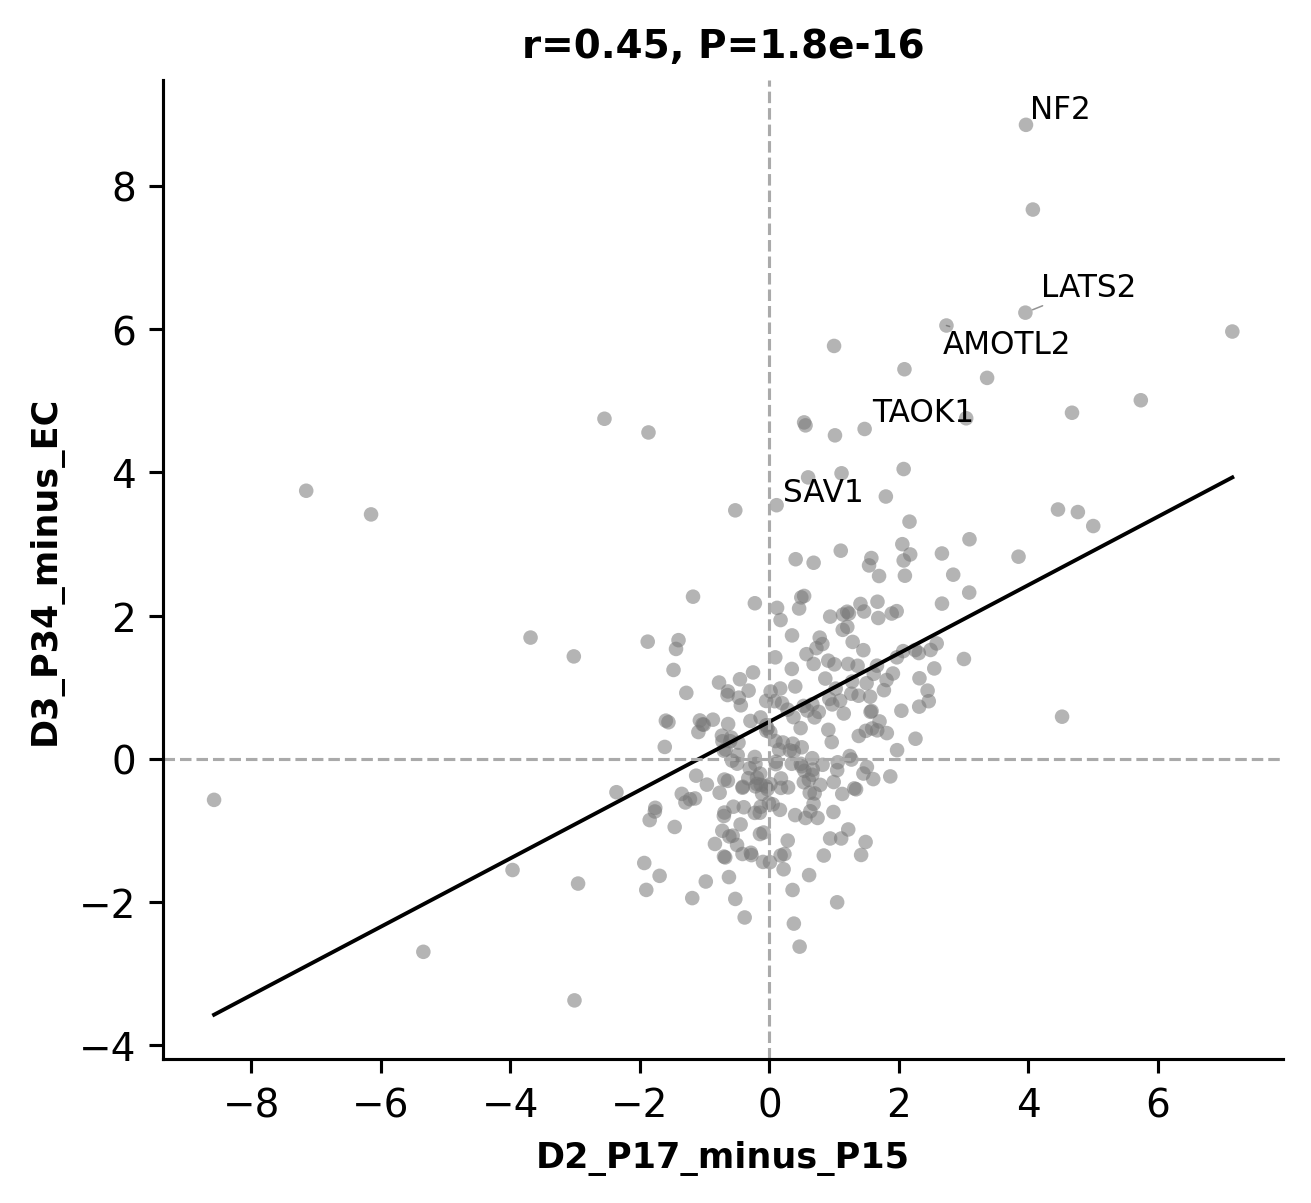

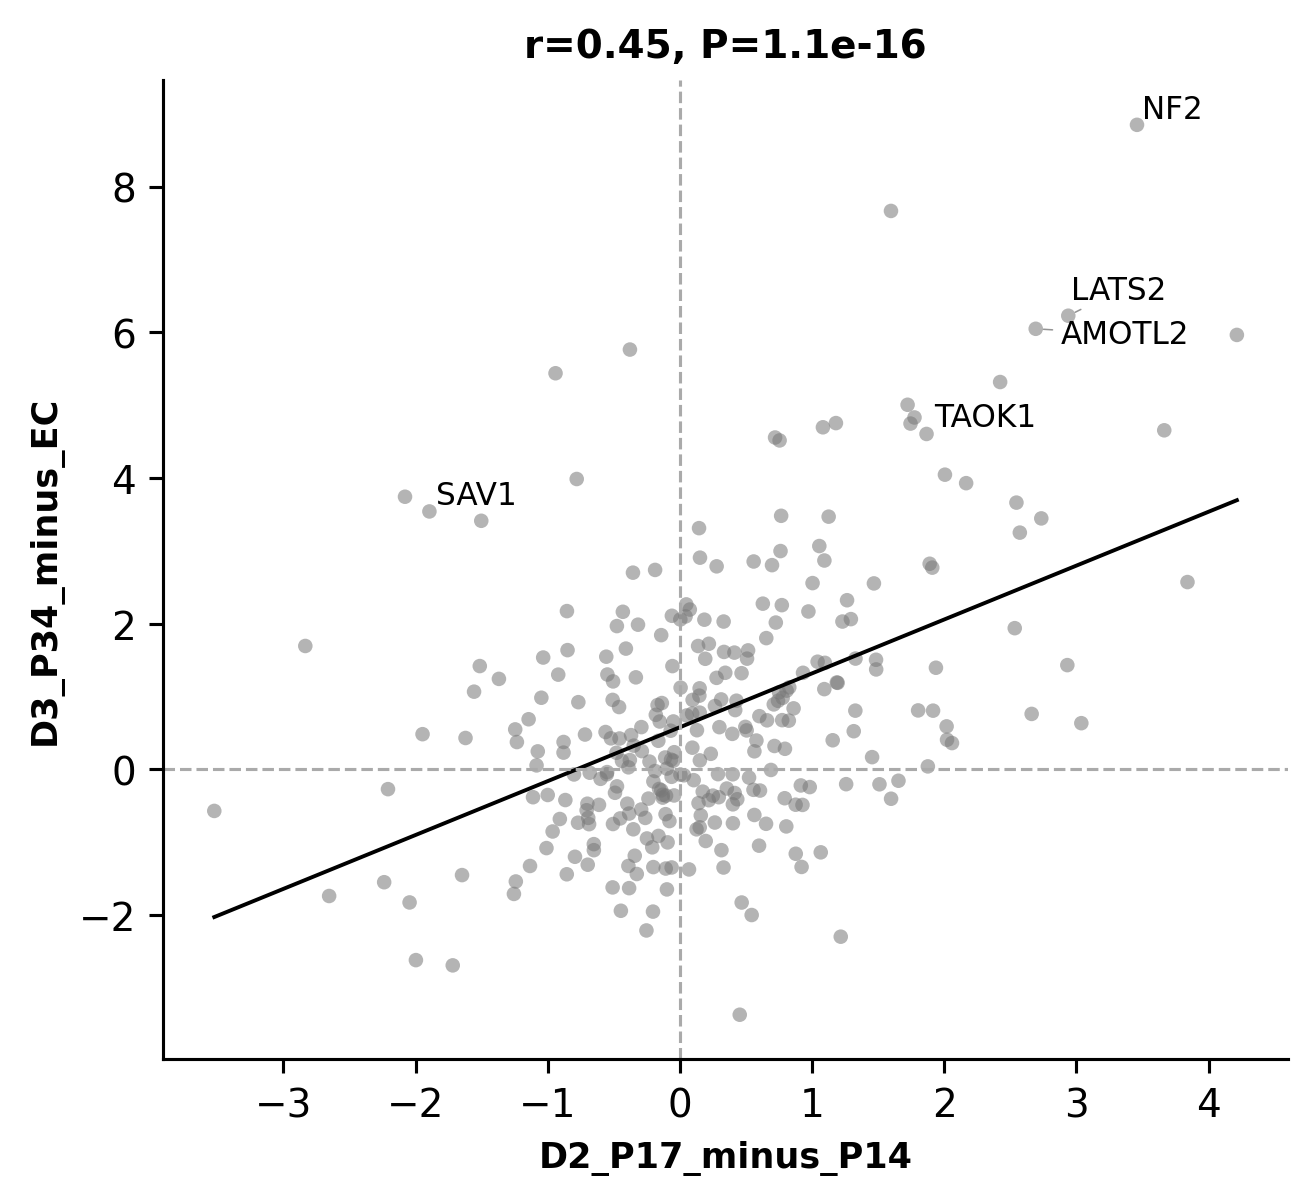

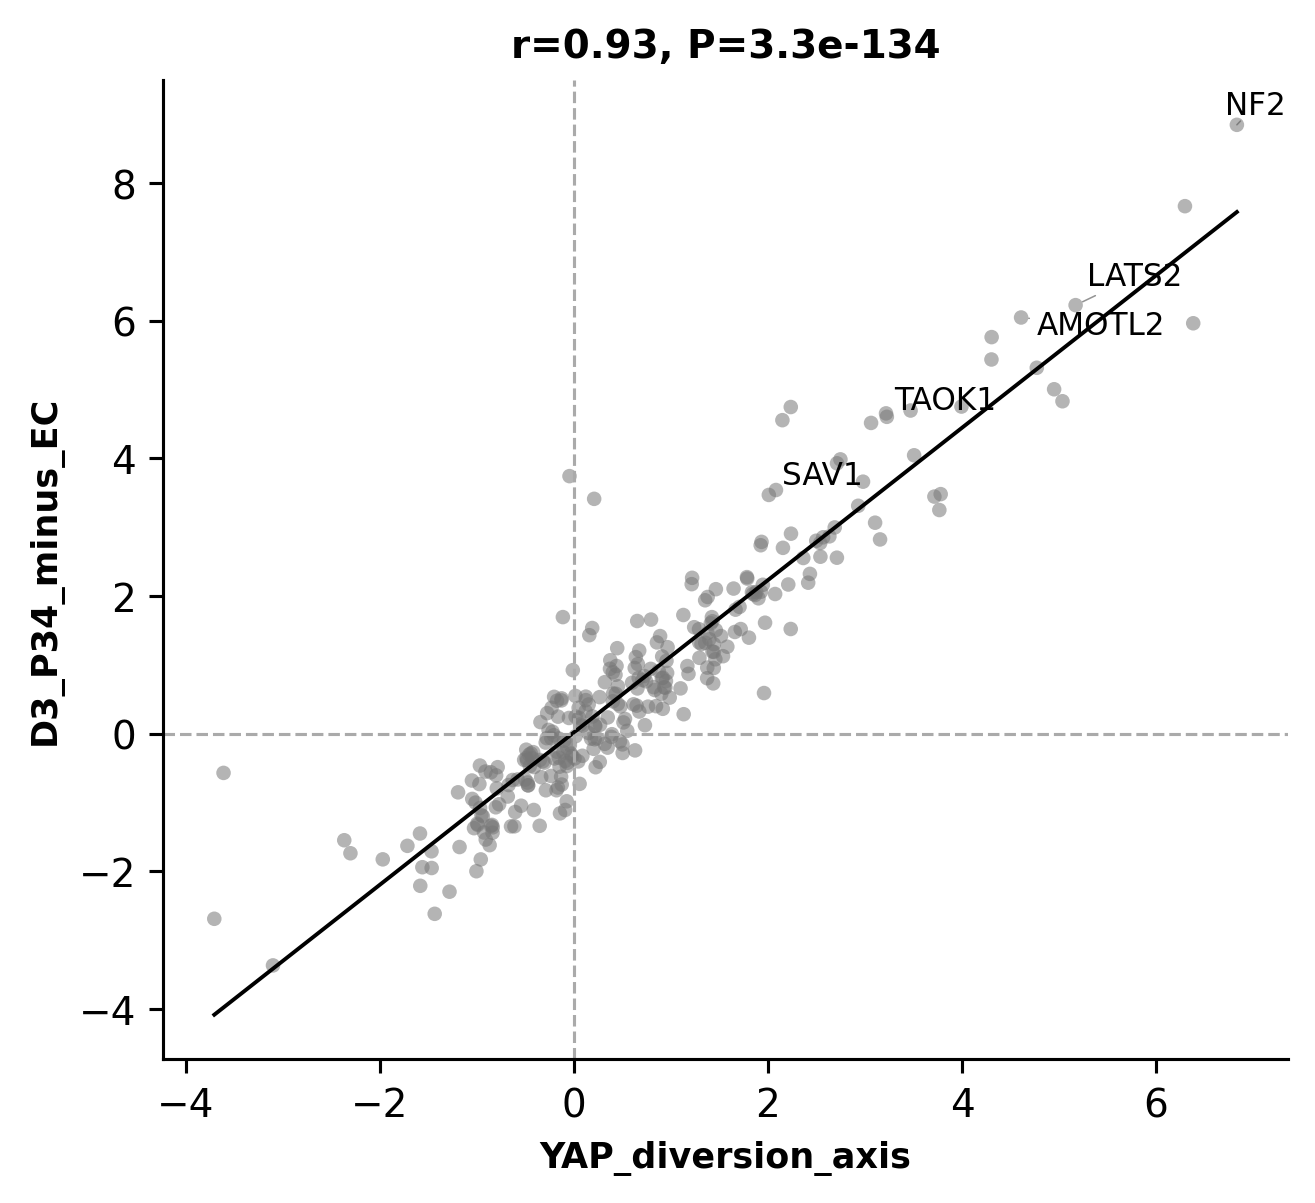

In [11]:

def axis_scatter(xcol, ycol, label_targets=None, out_prefix=None):
    dat = phenotypes[[xcol, ycol]].dropna().copy()
    x = dat[xcol]; y = dat[ycol]
    r, p = pearsonr(x, y)
    fig, ax = plt.subplots(figsize=(4.8, 4.4), dpi=280)
    ax.scatter(x, y, s=14, color="#777777", alpha=0.55, edgecolors='none')
    coef = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, coef[0]*xs + coef[1], color="black", lw=1.0)
    ax.axhline(0, ls="--", lw=0.8, color="#AAAAAA")
    ax.axvline(0, ls="--", lw=0.8, color="#AAAAAA")
    if label_targets:
        texts = []
        for t in label_targets:
            if t in dat.index:
                texts.append(ax.text(dat.loc[t, xcol], dat.loc[t, ycol], t, fontsize=8))
        if HAS_ADJUST_TEXT and texts:
            adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='#666666', lw=0.4, alpha=0.7), time_lim=1.0)
    ax.set_xlabel(xcol, fontsize=9, fontweight="bold")
    ax.set_ylabel(ycol, fontsize=9, fontweight="bold")
    ax.set_title(f"r={r:.2f}, P={p:.1e}", fontsize=10, fontweight="bold")
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    fig.tight_layout()
    if out_prefix:
        fig.savefig(os.path.join(OUTDIR, f"{out_prefix}.png"), dpi=300, bbox_inches="tight")
        fig.savefig(os.path.join(OUTDIR, f"{out_prefix}.pdf"), bbox_inches="tight")
        fig.savefig(os.path.join(OUTDIR, f"{out_prefix}.svg"), bbox_inches="tight")
    plt.show()

axis_scatter("D2_P17_minus_P15", "D3_P34_minus_EC", HIPPO_TARGETS, "scatter_D2_P17_minus_P15_vs_D3_P34_minus_EC")
axis_scatter("D2_P17_minus_P14", "D3_P34_minus_EC", HIPPO_TARGETS, "scatter_D2_P17_minus_P14_vs_D3_P34_minus_EC")
axis_scatter("YAP_diversion_axis", "D3_P34_minus_EC", HIPPO_TARGETS, "scatter_YAP_diversion_axis_vs_D3_P34_minus_EC")


## Convergence counts: how many targets affect each curated program?

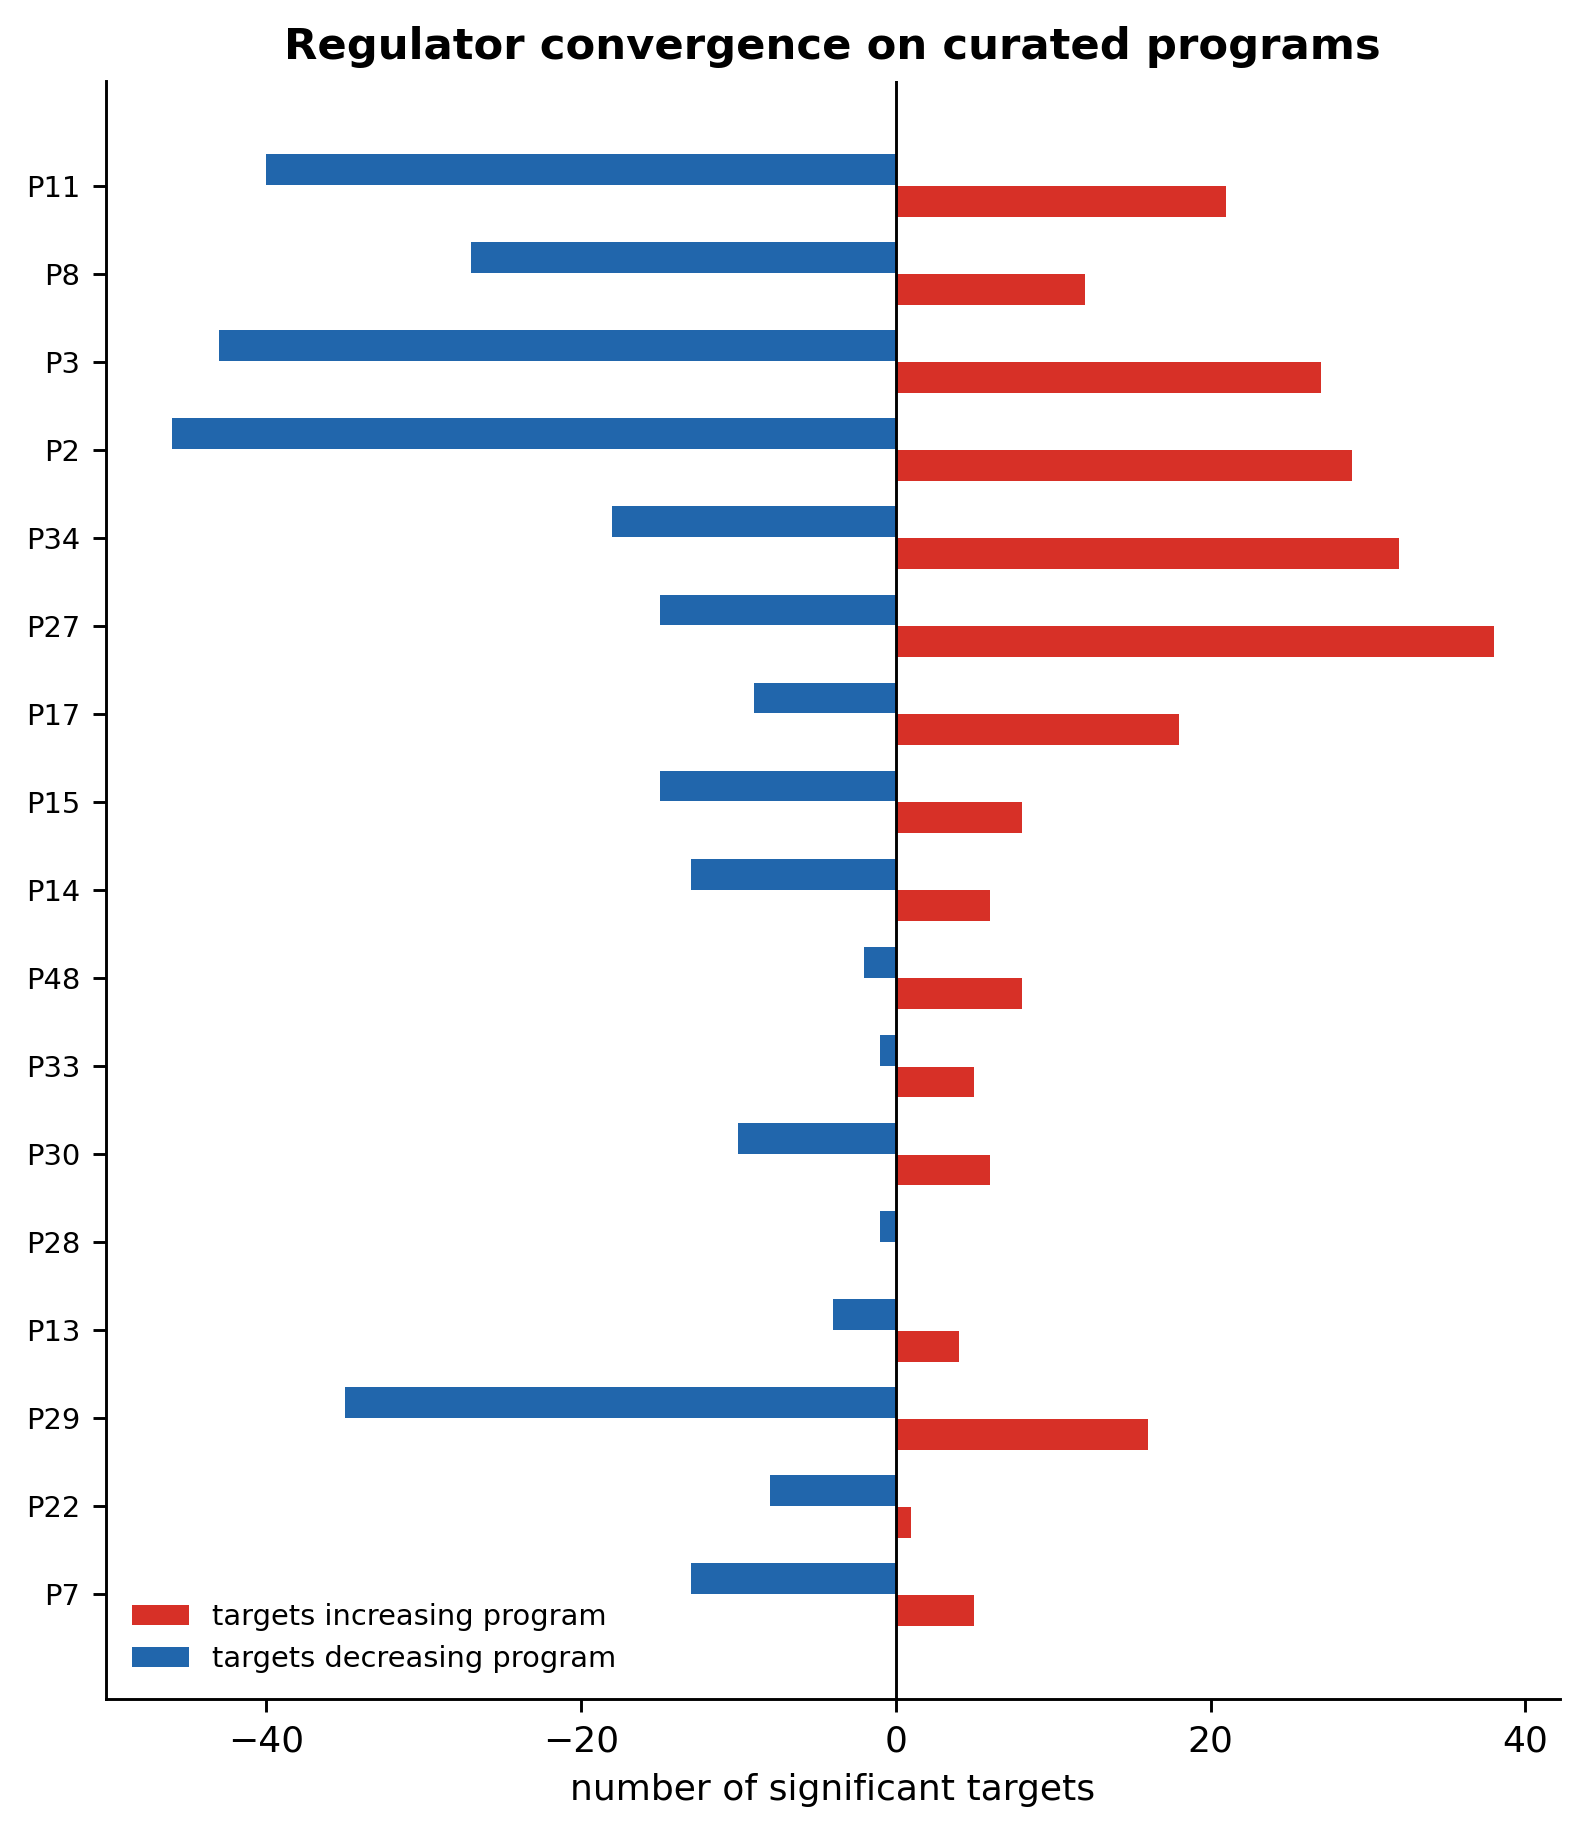

,program_id,program_label,n_up,n_down,mean_abs_effect
0,7,P7,5,13,0.336735
1,22,P22,1,8,0.365213
2,29,P29,16,35,0.533940
3,13,P13,4,4,0.273920
4,28,P28,0,1,0.377176
5,30,P30,6,10,0.590086
6,33,P33,5,1,0.521471
7,48,P48,8,2,0.598549
8,14,P14,6,13,0.588220
9,15,P15,8,15,0.688028


In [12]:

conv = []
for pid in effect_mat.columns:
    conv.append({
        "program_id": pid,
        "program_label": program_label_map.get(pid, f"P{pid}"),
        "n_up": int(((fdr_mat[pid] < FDR_CUTOFF) & (effect_mat[pid] > EFFECT_CUTOFF)).sum()),
        "n_down": int(((fdr_mat[pid] < FDR_CUTOFF) & (effect_mat[pid] < -EFFECT_CUTOFF)).sum()),
        "mean_abs_effect": effect_mat[pid].abs().mean(),
    })
conv = pd.DataFrame(conv)
conv.to_csv(os.path.join(OUTDIR, "program_convergence_counts.csv"), index=False)

y = np.arange(len(conv))
fig, ax = plt.subplots(figsize=(6.2, 0.35*len(conv)+1.2), dpi=260)
ax.barh(y - 0.18, conv["n_up"], height=0.35, color="#D73027", label="targets increasing program")
ax.barh(y + 0.18, -conv["n_down"], height=0.35, color="#2166AC", label="targets decreasing program")
ax.set_yticks(y)
ax.set_yticklabels(conv["program_label"], fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("number of significant targets")
ax.set_title("Regulator convergence on curated programs", fontsize=12, fontweight="bold")
ax.legend(frameon=False, fontsize=8)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "bar_program_convergence_counts.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(OUTDIR, "bar_program_convergence_counts.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUTDIR, "bar_program_convergence_counts.svg"), bbox_inches="tight")
plt.show()
display(conv)


## Program coupling classes

Group pairwise program correlations as within-day, adjacent-day, or distant-day relationships.

/tmp/ipykernel_18499/414420236.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=classes, showfliers=True)


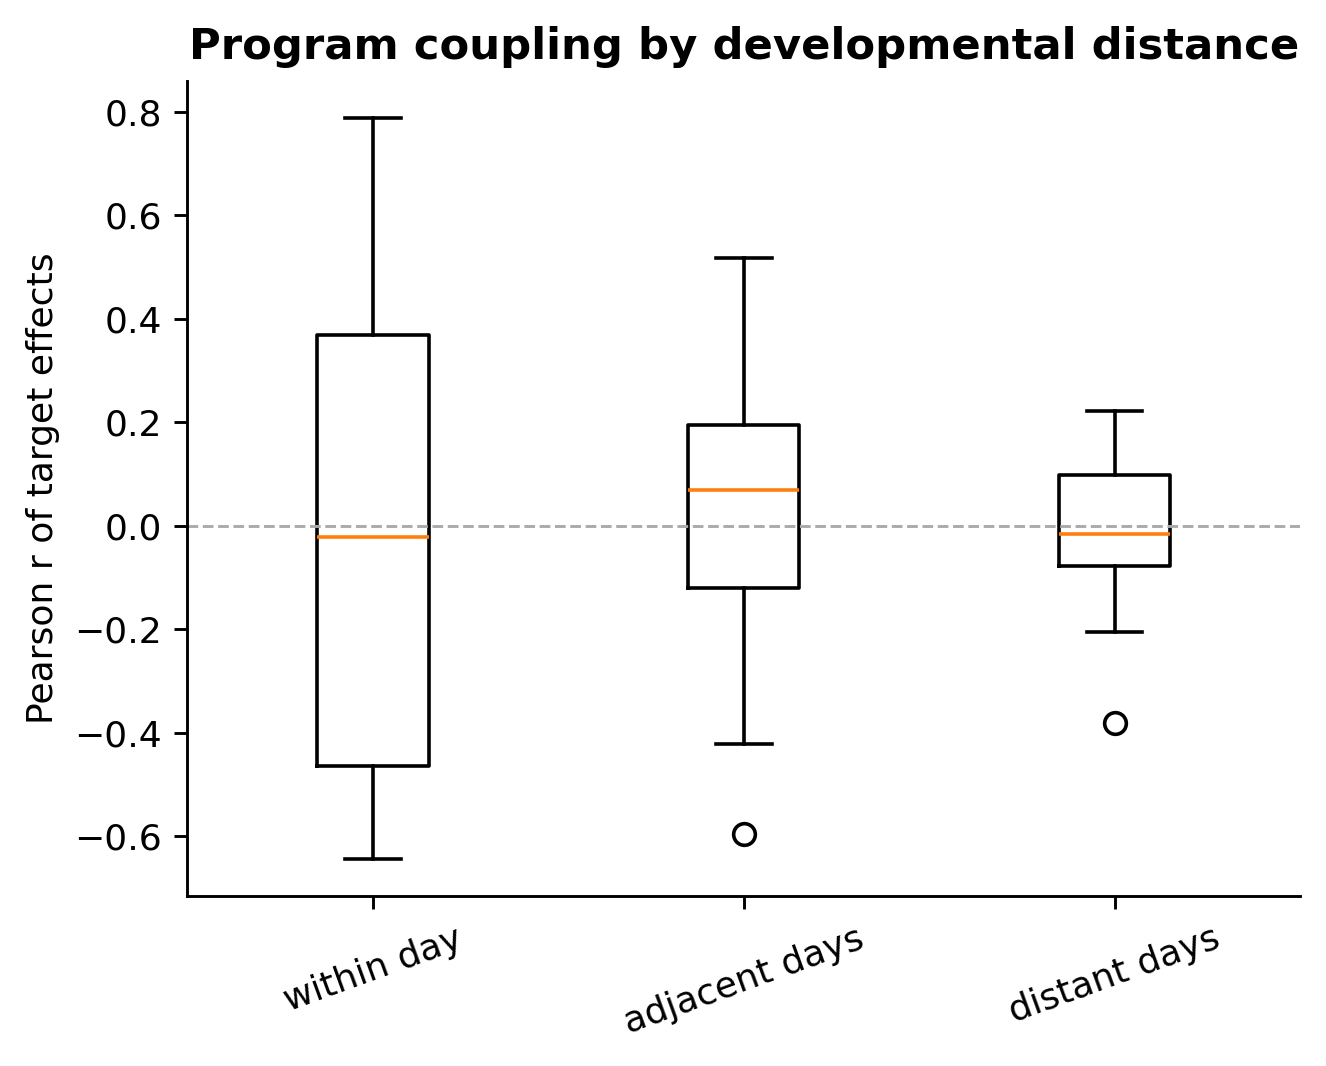

,program_a,program_b,label_a,label_b,day_a,day_b,day_pair_class,pearson_r,p_value,n_targets
126,34,2,P34,P2,D3,D3,within day,-0.644869,1.520131e-36,299
108,15,17,P15,P17,D2,D2,within day,-0.633681,5.619035e-35,299
74,30,17,P30,P17,D1,D2,adjacent days,-0.595654,4.234971e-30,299
128,34,8,P34,P8,D3,D3,within day,-0.582363,1.523250e-28,299
46,13,30,P13,P30,D1,D1,within day,-0.559402,5.116579e-26,299
129,34,11,P34,P11,D3,D3,within day,-0.535520,1.368989e-23,299
127,34,3,P34,P3,D3,D3,within day,-0.519968,4.134159e-22,299
124,27,8,P27,P8,D3,D3,within day,-0.484122,5.650527e-19,299
122,27,2,P27,P2,D3,D3,within day,-0.464250,2.177916e-17,299
123,27,3,P27,P3,D3,D3,within day,-0.464188,2.202287e-17,299


,program_a,program_b,label_a,label_b,day_a,day_b,day_pair_class,pearson_r,p_value,n_targets
121,27,34,P27,P34,D3,D3,within day,0.407057,2.318691e-13,299
116,17,34,P17,P34,D2,D3,adjacent days,0.449216,2.959155e-16,299
73,30,15,P30,P15,D1,D2,adjacent days,0.453738,1.368338e-16,299
51,13,17,P13,P17,D1,D2,adjacent days,0.518046,6.224319e-22,299
135,8,11,P8,P11,D3,D3,within day,0.617689,7.620025e-33,299
133,3,8,P3,P8,D3,D3,within day,0.624873,8.696247e-34,299
134,3,11,P3,P11,D3,D3,within day,0.675885,2.969559e-41,299
131,2,8,P2,P8,D3,D3,within day,0.755801,1.480051e-56,299
132,2,11,P2,P11,D3,D3,within day,0.773086,1.142161e-60,299
130,2,3,P2,P3,D3,D3,within day,0.788354,1.288526e-64,299


In [13]:

pairs = []
for i, a in enumerate(effect_mat.columns):
    for b in effect_mat.columns[i+1:]:
        dat = effect_mat[[a,b]].dropna()
        if len(dat) < 5: continue
        r, p = pearsonr(dat[a], dat[b])
        da, db = program_stage_map.get(a), program_stage_map.get(b)
        order = {"D0":0,"D1":1,"D2":2,"D3":3}
        delta = abs(order.get(da, np.nan) - order.get(db, np.nan))
        if delta == 0: cls = "within day"
        elif delta == 1: cls = "adjacent days"
        elif delta >= 2: cls = "distant days"
        else: cls = "unknown"
        pairs.append({"program_a": a, "program_b": b, "label_a": program_label_map.get(a), "label_b": program_label_map.get(b), "day_a": da, "day_b": db, "day_pair_class": cls, "pearson_r": r, "p_value": p, "n_targets": len(dat)})
pair_df = pd.DataFrame(pairs)
pair_df.to_csv(os.path.join(OUTDIR, "curated_program_pair_correlations_by_day_class.csv"), index=False)

fig, ax = plt.subplots(figsize=(5.2, 4.2), dpi=260)
classes = ["within day", "adjacent days", "distant days"]
data = [pair_df.loc[pair_df.day_pair_class==c, "pearson_r"].dropna() for c in classes]
ax.boxplot(data, labels=classes, showfliers=True)
ax.axhline(0, color="#AAAAAA", lw=0.8, ls="--")
ax.set_ylabel("Pearson r of target effects")
ax.set_title("Program coupling by developmental distance", fontsize=12, fontweight="bold")
ax.tick_params(axis='x', rotation=20)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout()
fig.savefig(os.path.join(OUTDIR, "boxplot_program_coupling_by_day_class.png"), dpi=300, bbox_inches="tight")
fig.savefig(os.path.join(OUTDIR, "boxplot_program_coupling_by_day_class.pdf"), bbox_inches="tight")
fig.savefig(os.path.join(OUTDIR, "boxplot_program_coupling_by_day_class.svg"), bbox_inches="tight")
plt.show()
display(pair_df.sort_values('pearson_r').head(10))
display(pair_df.sort_values('pearson_r').tail(10))


## Target module discovery from curated program-effect profiles

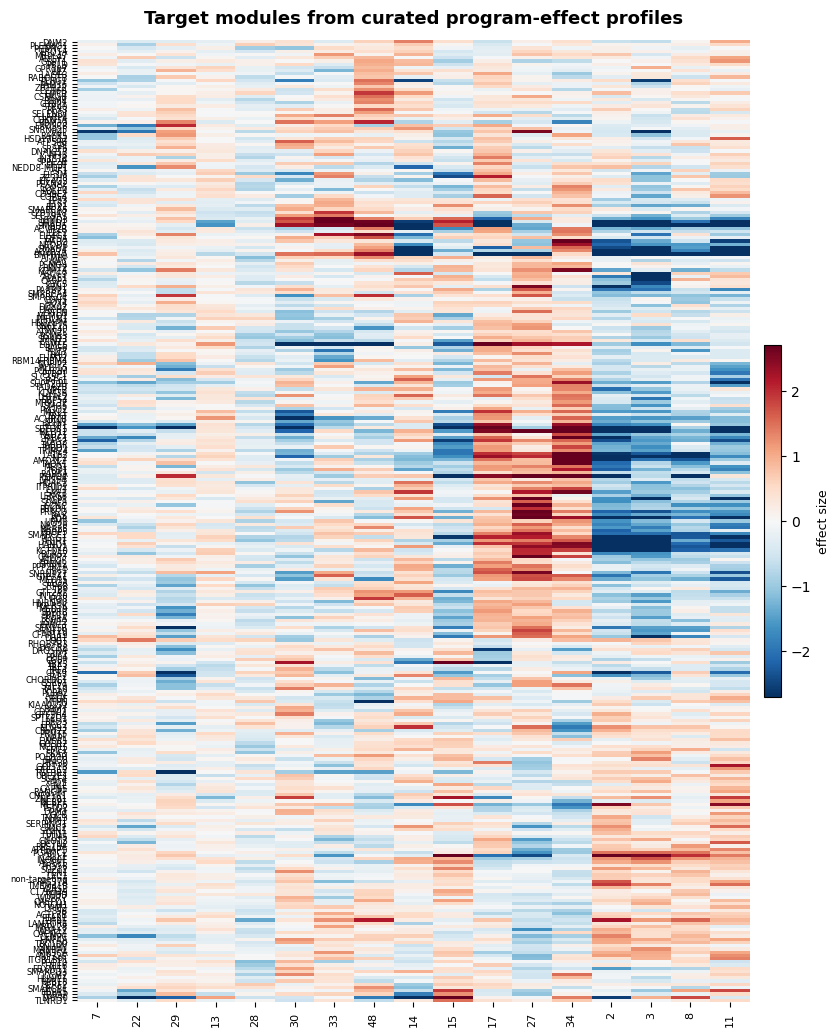

In [14]:

# Cluster targets by curated program-effect vectors.
mat = effect_mat.fillna(0)
row_order = cluster_rows(mat, metric="correlation", method="average")

# Plot clustered heatmap without relying on seaborn.
plot_heatmap(
    effect_mat,
    row_order=row_order,
    col_order=program_order,
    title="Target modules from curated program-effect profiles",
    figsize=(8.5, max(6, 0.035*len(row_order))),
    out=os.path.join(OUTDIR, "heatmap_target_modules_curated_program_effects")
)

# Export target order for reuse.
pd.DataFrame({"target": row_order, "cluster_order": np.arange(len(row_order))}).to_csv(os.path.join(OUTDIR, "target_order_by_program_effect_clustering.csv"), index=False)


## Kyle-oriented P14/P17 top loading genes

This is program-level, not cluster-level.

In [15]:

# If the spreadsheet Summary sheet exists, use it to export top genes for P14/P17/P15/P34.
try:
    summary = pd.read_excel(CNMF_XLSX, sheet_name="Summary")
    top_rows = summary[summary["program_name"].isin([14,17,15,34,27,2,3,8,11])].copy()
    top_rows.to_csv(os.path.join(OUTDIR, "selected_program_top_loaded_genes_from_summary.csv"), index=False)
    display(top_rows[[c for c in ["program_name", "top10_loaded_genes", "manual_annotation_label", "manual_timepoint"] if c in top_rows.columns]])
except Exception as e:
    print("Could not load Summary sheet. This is optional.")
    print(e)


,program_name,top10_loaded_genes,manual_annotation_label,manual_timepoint
2,2,MECOM;FBXL7;RP1;DOCK4;FLT1;NRP1;VAV3;GALNT18;P...,NaN,NaN
3,3,CALM1;TMSB10;LBH;TMSB4X;GNG11;PLK2;RALB;ESM1;L...,NaN,NaN
8,8,RNU4-2;RN7SK;7SK-1;RNU4-1;ENSG00000278996;ENSG...,NaN,NaN
11,11,EDN1;ANGPT2;ESM1;BMP6;HECW2;APLN;CYTOR;MIR4435...,NaN,NaN
14,14,ROR1;RIMS2;TBX20;CLSTN2;LGR4;HAND1;ALCAM;ATP2B...,NaN,NaN
15,15,HAPLN1;SORBS1;APLNR;KDR;LDB2;NRP2;TAL1;IFI16;F...,NaN,NaN
17,17,AHNAK;SLC8A1;RALYL;CDH1;LCP1;DMD;CXCL12;PCDH11...,NaN,NaN
27,27,COL3A1;CCDC80;COL1A1;RSPO2;SLC22A3;GATA4;SLIT3...,NaN,NaN
34,34,ACTC1;TAGLN;ANKRD1;KRT18;TPM1;ACTA1;ACTA2;KRT8...,NaN,NaN


## Package outputs

In [16]:

import zipfile
zip_path = OUTDIR + ".zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUTDIR):
        for fn in files:
            fp = os.path.join(root, fn)
            z.write(fp, arcname=os.path.relpath(fp, OUTDIR))
print("Packaged:", zip_path)


Packaged: outputs_program_level_temporal_phenotypes_v4.zip
